In [83]:
from langgraph.graph import StateGraph, START, END
from langchain_groq import ChatGroq
import os
from dotenv import load_dotenv
from pydantic import BaseModel
from typing import Literal

In [84]:
load_dotenv()

model = os.getenv('GROQ_MODEL')
api_key = os.getenv('GROQ_API_KEY')
llm = ChatGroq(model=model, api_key=api_key)

In [85]:
class IssueType(BaseModel):
    issue_type:Literal["payment","delivery","product"]
    
structure_llm = llm.with_structured_output(IssueType)

In [86]:
class EcomState(BaseModel):
    query: str = ""
    type: Literal["payment","delivery","product"] = ""
    result: str = ""

In [87]:
def identify_type(state:EcomState):
    """Identify the type of query"""
    res = structure_llm.invoke(state.query)
    state.type = res.issue_type
    return state

def payment_issue(state:EcomState):
    state.result = "Payment Query Resolved"
    return state

def delivery_issue(state:EcomState):
    state.result = "Delivery Query Resolved"
    return state

def product_issue(state:EcomState):
    state.result = "Product Query Resolved"
    return state

# def conditional_node(state:EcomState)->Literal["payment_issue","delivery_issue","product_issue"]:
#     if state.type == "payment":
#         return "payment_issue"
#     elif state.type == "delivery":
#         return "delivery_issue"
#     else:
#         return "product_issue"

def conditional_node(state:EcomState)->Literal["payment","delivery","product"]:
    return state.type

In [88]:
graph = StateGraph(EcomState)

graph.add_node("identify_type", identify_type)
graph.add_node("payment_issue", payment_issue)
graph.add_node("delivery_issue", delivery_issue)
graph.add_node("product_issue", product_issue)

graph.add_edge(START, "identify_type")
# graph.add_conditional_edges("identify_type", conditional_node)
graph.add_conditional_edges("identify_type", conditional_node, {"payment":"payment_issue","delivery":"delivery_issue","product":"product_issue"})
graph.add_edge("payment_issue", END)
graph.add_edge("delivery_issue", END)
graph.add_edge("product_issue", END)

app = graph.compile()

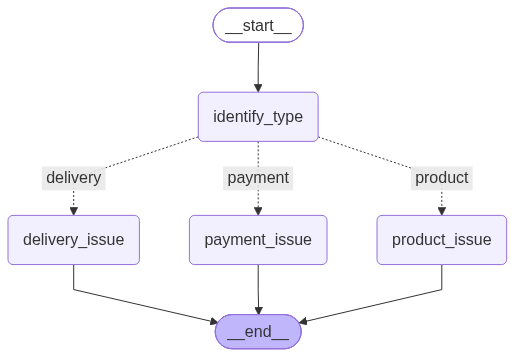

In [89]:
app

In [90]:
# res = app.invoke({"query":"I haven't received my order"})
# res = app.invoke({"query":"I haven't received my refund"})
result = app.invoke({"query":"I have received wrong order"})
result["result"]

'Product Query Resolved'